# 41 · Validación del suelo: WoSIS, mapa del IGAC y mapas finales del kriging

**Autora:** Katalina (`@kataleyva`)

| Concepto | Cómo se define |
|---|---|
| **Entradas** | `datos/comunes/altillanura_municipios.gpkg` (cuaderno 01, Michelle) · `datos/suelos/soilgrids/` (cuaderno 40): `soilgrids_ph_0_30.tif`, `soilgrids_cos_gkg_0_30.tif`, `kriging_*.tif`, `resumen_validacion_soilgrids.csv`, `benchmark_idw_vs_kriging.csv` · `datos/suelos/wosis/` (perfiles WoSIS por WFS; se descargan si no existen) · `datos/suelos/igac/igac_ph_poligonos_meta_vichada.gpkg` (mapa de propiedades químicas del IGAC, 2016) |
| **Salidas** | `modulos/suelos/resultados/41_tabla_validacion.csv` (tabla final de validación) · `modulos/suelos/resultados/41_wosis_sitios.csv` (sitios WoSIS 0-30 cm con lo que predicen SoilGrids y el kriging) · `modulos/suelos/resultados/41_igac_concordancia.csv` · `modulos/suelos/resultados/41_suelo_por_paisaje.csv` · `modulos/suelos/resultados/41_clases_ph_area.csv` · figuras en `modulos/suelos/graficas/` |
| **Lo usan** | Informe (capítulos 4 y 5) y presentación |
| **Sistema de coordenadas** | EPSG:9377 (MAGNA-SIRGAS Origen Nacional); SoilGrids se lee en su grilla original EPSG:4326 |
| **Datos pesados** | `datos/suelos/wosis/` y `datos/suelos/igac/` van en DVC, no en Git |

**Pregunta:** ¿qué tan buenos son los mapas de suelo que usa el proyecto cuando se comparan con datos medidos?

El cuaderno 40 valida el kriging contra el propio SoilGrids (la "verdad conocida"). Eso dice cuánto pierde el kriging al interpolar, pero no si SoilGrids se parece al suelo real. Aquí se hace la **validación externa** (sección 11.4 de la ruta de trabajo):

1. **WoSIS**: perfiles de suelo medidos en laboratorio. Se comparan con SoilGrids y con el kriging en los mismos sitios (RMSE, ME, MSSE, R²).
2. **Mapa de pH del IGAC**: cartografía oficial en clases. Se mide la concordancia con SoilGrids con el **kappa de Cohen**.
3. **Mapas finales** de predicción y varianza del kriging, y mapa de clases de pH, para el informe y la presentación.
4. **Tabla final de validación**, que junta lo del 40 (validación interna) y lo de este cuaderno (validación externa).

In [1]:
import sys, subprocess
if 'google.colab' in sys.modules:   # Colab no trae estas librerías
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'rasterio'], check=True)

import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch
import requests
import rasterio
from rasterio import features
from scipy import stats
from IPython.display import display

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
plt.rcParams["figure.dpi"] = 100


# Rutas del proyecto: funcionan en Colab y en local (celda estándar de 00_configuracion)
import os
EN_COLAB = 'google.colab' in sys.modules
REPO = 'https://github.com/DanielFelipeRuizBermudez/Proyecto-ALTILLANURA.git'

if EN_COLAB:
    RAIZ = '/content/Proyecto-ALTILLANURA'
    if not os.path.exists(RAIZ):
        subprocess.run(['git', 'clone', '-q', REPO, RAIZ], check=True)
    os.chdir(RAIZ)
else:
    RAIZ = os.path.abspath(os.path.join('..', '..'))   # el cuaderno está en notebooks/40_suelos/


def traer(ruta):
    """Baja de DVC un archivo o carpeta pesada del repo si todavía no está."""
    if os.path.exists(os.path.join(RAIZ, ruta)):
        return
    if EN_COLAB:
        from google.colab import auth
        auth.authenticate_user()
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'dvc[gs]'], check=True)
    subprocess.run([sys.executable, '-m', 'dvc', 'pull', '-q', ruta], cwd=RAIZ, check=True)
    print('Bajado de DVC:', ruta)


COMUNES = Path(RAIZ) / "datos" / "comunes"
SUELOS = Path(RAIZ) / "datos" / "suelos"
SG = SUELOS / "soilgrids"
WOSIS = SUELOS / "wosis"
IGAC = SUELOS / "igac"
RES = Path(RAIZ) / "modulos" / "suelos" / "resultados"
GRAF = Path(RAIZ) / "modulos" / "suelos" / "graficas"
RES.mkdir(parents=True, exist_ok=True)
GRAF.mkdir(parents=True, exist_ok=True)
print("Raíz del repo:", RAIZ)

CRS_M = "EPSG:9377"
BBOX = (-73.6, 2.4, -67.4, 6.4)      # lon_min, lat_min, lon_max, lat_max (misma caja de la descarga de SoilGrids)
SEMILLA = 42
# Clases de pH (sección 14.3 de la ruta): mismos cortes que el cuaderno 42
CLASES_PH = [(-np.inf, 4.5, "extremadamente ácido (< 4,5)"),   # cortes exactos en la celda D.2
             (4.5, 5.0, "muy fuertemente ácido (4,5-5,0)"),
             (5.0, 5.5, "fuertemente ácido (5,0-5,5]"),
             (5.5, np.inf, "moderadamente ácido o más (> 5,5)")]


def fuente(texto):
    """Pie de figura con la fuente (regla de figuras del equipo)."""
    plt.figtext(0.01, -0.02, texto, fontsize=8, ha="left")


def metricas(obs, pred):
    obs, pred = np.asarray(obs, float), np.asarray(pred, float)
    e = pred - obs
    return {"n": len(obs), "RMSE": np.sqrt(np.mean(e ** 2)), "MAE": np.mean(np.abs(e)), "ME": np.mean(e),
            "R2": 1 - np.sum(e ** 2) / np.sum((obs - obs.mean()) ** 2),
            "r_Spearman": stats.spearmanr(obs, pred)[0] if len(obs) > 2 else np.nan}


def msse(z, pred, var):
    """Error cuadrático estandarizado medio: ≈ 1 si la varianza del kriging describe bien el error."""
    return float(np.mean((np.asarray(z) - np.asarray(pred)) ** 2 / np.asarray(var)))


def kappa_cohen(a, b, etiquetas):
    """Kappa de Cohen a partir de la tabla de concordancia (sin depender de scikit-learn)."""
    t = pd.crosstab(pd.Categorical(a, etiquetas), pd.Categorical(b, etiquetas), dropna=False).values.astype(float)
    n = t.sum()
    po = np.trace(t) / n
    pe = (t.sum(0) * t.sum(1)).sum() / n ** 2
    return po, (po - pe) / (1 - pe) if pe < 1 else np.nan

Raíz del repo: c:\Proyectos\Proyecto-ALTILLANURA


## A. Datos de entrada

### A.1 Límites municipales comunes (DANE MGN 2025, cuaderno 01)

In [2]:
traer("datos/comunes/altillanura_municipios.gpkg")
mun = gpd.read_file(COMUNES / "altillanura_municipios.gpkg")
mun["mpio_cdpmp"] = mun["mpio_cdpmp"].astype(str).str.zfill(5)
mun["municipio"] = mun["mpio_cnmbr"].str.title()
mun_m = mun.to_crs(CRS_M)
mun_g = mun.to_crs("EPSG:4326")
print(f"{len(mun)} municipios | área = {mun_m.area.sum() / 1e6:,.0f} km²")

traer("datos/suelos/soilgrids")
for f in ["soilgrids_ph_0_30.tif", "soilgrids_cos_gkg_0_30.tif", "kriging_ph_0_30.tif",
          "kriging_ph_0_30_varianza.tif", "kriging_cos_0_30_gkg.tif", "kriging_cos_0_30_varianza_log.tif"]:
    assert (SG / f).exists(), f"Falta {f}: ejecuta primero el cuaderno 40"
print("Rasters del cuaderno 40: OK")

7 municipios | área = 135,649 km²
Rasters del cuaderno 40: OK


### A.2 Perfiles de WoSIS (ISRIC)

**WoSIS** (*World Soil Information Service*) es la base de perfiles de suelo medidos en laboratorio que mantiene ISRIC; es la misma base con la que se entrenó SoilGrids. Se baja por su servicio WFS (`maps.isric.org/mapserv?map=/map/wosis_latest.map`) dentro de la misma caja de la descarga de SoilGrids:

* `profiles`: un punto por perfil, con año e incertidumbre de posición.
* `orgc` (carbono orgánico, g/kg) y `phaq` (pH en agua): una fila por horizonte, con su profundidad superior e inferior.

Si los archivos ya están en `datos/suelos/wosis/` (DVC) no se vuelven a bajar.

In [3]:
WFS = "https://maps.isric.org/mapserv?map=/map/wosis_latest.map"
CAPAS_WOSIS = ["profiles", "orgc", "phaq"]


def descargar_wfs(capa, destino, pagina=1000):
    feats, inicio = [], 0
    while True:
        params = {"SERVICE": "WFS", "VERSION": "2.0.0", "REQUEST": "GetFeature",
                  "TYPENAMES": f"ms:wosis_latest_{capa}", "OUTPUTFORMAT": "application/json; subtype=geojson",
                  # En WFS 2.0 con EPSG:4326 el orden del BBOX es lat, lon
                  "BBOX": f"{BBOX[1]},{BBOX[0]},{BBOX[3]},{BBOX[2]},urn:ogc:def:crs:EPSG::4326",
                  "COUNT": pagina, "STARTINDEX": inicio}
        r = requests.get(WFS, params=params, timeout=600)
        r.raise_for_status()
        d = r.json()
        feats += d["features"]
        if len(d["features"]) < pagina:
            break
        inicio += len(d["features"])
    destino.write_text(json.dumps({"type": "FeatureCollection", "features": feats}), encoding="utf-8")
    print(f"{destino.name}: {len(feats)} registros descargados")


archivos_wosis = {c: WOSIS / f"wosis_{c}_altillanura_bbox.geojson" for c in CAPAS_WOSIS}
if not all(f.exists() for f in archivos_wosis.values()):
    try:
        traer("datos/suelos/wosis")
    except Exception as e:
        print("No está en DVC todavía, se descarga de ISRIC:", e)
WOSIS.mkdir(parents=True, exist_ok=True)
for c, f in archivos_wosis.items():
    if not f.exists():
        descargar_wfs(c, f)

perf_caja = gpd.read_file(archivos_wosis["profiles"]).to_crs("EPSG:4326")
perf_caja = gpd.sjoin(perf_caja, mun_g[["mpio_cdpmp", "municipio", "geometry"]], predicate="within", how="left")
perf_caja = perf_caja.drop(columns="index_right")
print(f"Perfiles en la caja: {len(perf_caja)} | dentro de los 7 municipios: {perf_caja['mpio_cdpmp'].notna().sum()}")
display(perf_caja.groupby(perf_caja["municipio"].fillna("fuera de los municipios")).size().rename("perfiles").to_frame())
display(perf_caja[["year", "positional_uncertainty"]].astype(str).value_counts().rename("perfiles").to_frame().head(10))

Perfiles en la caja: 79 | dentro de los 7 municipios: 35


,perfiles
municipio,
Cumaribo,16
Puerto Gaitán,15
Puerto López,4
fuera de los municipios,44


perfiles
year positional_uncertainty          
1973 Over 10 km                    17
1981 Over 10 km                    13
1972 Circa 100 m                    7
1988 Over 10 km                     6
     1 km - 10 km                   6
1975 Over 10 km                     4
1979 Over 10 km                     4
1978 1 km - 10 km                   4
1987 1 km - 10 km                   4
1974 Over 10 km                     2

### A.3 Valores 0-30 cm por sitio

Mismo procedimiento del cuaderno 40 para SoilGrids, ahora con datos medidos:

1. Se quitan horizontes orgánicos superficiales y horizontes con profundidades incoherentes.
2. Se promedia cada perfil en 0-30 cm ponderando por el espesor de cada horizonte. Se exige que los horizontes cubran al menos 20 de los 30 cm y que el primero empiece a 5 cm o menos.
3. Los perfiles con la misma coordenada (el mismo sitio repetido en dos proyectos) se promedian. El kriging y las métricas trabajan con **sitios**, no con perfiles.

Se usan dos conjuntos: los **sitios dentro de los 7 municipios** y **todos los sitios de la caja** (incluye vecinos fuera de los municipios, con el mismo tipo de suelo).

In [4]:
def leer_propiedad(capa, nombre):
    g = gpd.read_file(archivos_wosis[capa])
    df = pd.DataFrame(g.drop(columns="geometry"))
    return df[["profile_id", "layer_id", "upper_depth", "lower_depth", "organic_surface", "value_avg"]] \
        .rename(columns={"value_avg": nombre})


claves = ["profile_id", "layer_id", "upper_depth", "lower_depth", "organic_surface"]
capas = leer_propiedad("orgc", "cos_gkg").merge(leer_propiedad("phaq", "ph"), on=claves, how="outer")
capas = capas[(~capas["organic_surface"].astype(bool)) & (capas["lower_depth"] > capas["upper_depth"])].drop_duplicates()
assert capas["ph"].dropna().between(2, 11).all() and capas["cos_gkg"].dropna().between(0, 600).all()


def prom_0_30(df, col, prof=30, cobertura_min=20, sup_max=5):
    d = df.dropna(subset=[col]).copy()
    d["esp"] = (np.minimum(d["lower_depth"], prof) - np.maximum(d["upper_depth"], 0)).clip(lower=0)
    d = d[d["esp"] > 0]

    def f(g):
        ok = (g["esp"].sum() >= cobertura_min) and (g["upper_depth"].min() <= sup_max)
        return np.average(g[col], weights=g["esp"]) if ok else np.nan
    return d.groupby("profile_id")[[col, "esp", "upper_depth"]].apply(f).rename(col)


p030 = pd.concat([prom_0_30(capas, "cos_gkg"), prom_0_30(capas, "ph")], axis=1)
perf = perf_caja.merge(p030, left_on="profile_id", right_index=True, how="left")
perf["lon"], perf["lat"] = perf.geometry.x.round(4), perf.geometry.y.round(4)

sitios = (perf.dropna(subset=["cos_gkg", "ph"], how="all")
          .groupby(["lon", "lat"])
          .agg(cos_gkg=("cos_gkg", "mean"), ph=("ph", "mean"), n_perfiles=("profile_id", "size"),
               anio=("year", "median"), incert_posicion=("positional_uncertainty", "first"),
               mpio_cdpmp=("mpio_cdpmp", "first"), municipio=("municipio", "first"))
          .reset_index())
sitios["en_municipios"] = sitios["mpio_cdpmp"].notna()
sitios = gpd.GeoDataFrame(sitios, geometry=gpd.points_from_xy(sitios["lon"], sitios["lat"]), crs="EPSG:4326")
print(f"Sitios con dato 0-30 cm en la caja: {len(sitios)} | dentro de los municipios: {sitios['en_municipios'].sum()}")
display(sitios.groupby("en_municipios")[["cos_gkg", "ph"]].describe().T.round(2))

Sitios con dato 0-30 cm en la caja: 27 | dentro de los municipios: 9


en_municipios  False  True 
cos_gkg count  18.00   9.00
        mean   12.72  14.40
        std    14.46   8.75
        min     2.88   1.58
        25%     5.62   8.23
        50%     8.74  15.31
        75%    12.95  20.06
        max    67.00  27.47
ph      count  18.00   9.00
        mean    4.75   4.87
        std     0.50   0.21
        min     4.06   4.64
        25%     4.46   4.73
        50%     4.78   4.81
        75%     4.92   5.00
        max     5.98   5.30

## B. Validación externa con WoSIS

En cada sitio de WoSIS se lee:

* el píxel de **SoilGrids** 0-30 cm (≈ 278 m) donde cae el sitio;
* la celda del **kriging** del cuaderno 40 (2 km), con su varianza. El kriging solo existe dentro de los 7 municipios.

**Métricas** (prioridad de la sección 11.4 de la ruta): **RMSE** (error típico, en las unidades de la variable), **ME** (sesgo: positivo = el mapa sobreestima), **MSSE** (≈ 1 si la varianza del kriging describe bien el error real), y **R²** y **MAE** como complementarias. Un R² negativo significa que el mapa predice peor que poner el promedio de los sitios en todas partes.

**MSSE del COS:** el kriging se hizo en log(COS), así que el MSSE se calcula en esa escala: `(log(obs) − log(pred_mediana))² / var`, con `log(pred_mediana) = log(pred) − var/2` (se deshace la corrección lognormal del cuaderno 40).

**Cuidado con la lectura:** casi todos los perfiles son de 1973-1988 y muchos tienen error de posición declarado de 1 a más de 10 km. Una diferencia con el mapa puede ser del mapa, de la ubicación del perfil o de un cambio real del suelo en 40 años.

In [5]:
def leer_en_puntos(f, gdf):
    with rasterio.open(f) as src:
        pts = gdf.to_crs(src.crs)
        v = np.array([s[0] for s in src.sample(zip(pts.geometry.x, pts.geometry.y))], dtype="float64")
        if src.nodata is not None and np.isfinite(src.nodata):
            v[v == src.nodata] = np.nan
    v[~np.isfinite(v)] = np.nan
    return v


sitios["ph_soilgrids"] = leer_en_puntos(SG / "soilgrids_ph_0_30.tif", sitios)
sitios["cos_soilgrids"] = leer_en_puntos(SG / "soilgrids_cos_gkg_0_30.tif", sitios)
sitios["ph_kriging"] = leer_en_puntos(SG / "kriging_ph_0_30.tif", sitios)
sitios["ph_kriging_var"] = leer_en_puntos(SG / "kriging_ph_0_30_varianza.tif", sitios)
sitios["cos_kriging"] = leer_en_puntos(SG / "kriging_cos_0_30_gkg.tif", sitios)
sitios["cos_kriging_var_log"] = leer_en_puntos(SG / "kriging_cos_0_30_varianza_log.tif", sitios)
# El kriging solo es válido dentro de los municipios (fuera, la celda está enmascarada)
sitios.loc[~sitios["en_municipios"], ["ph_kriging", "ph_kriging_var", "cos_kriging", "cos_kriging_var_log"]] = np.nan

filas = []
for prop, obs_c, nombre in [("pH 0-30 cm", "ph", "pH"), ("COS 0-30 cm (g/kg)", "cos_gkg", "COS")]:
    sg_c = "ph_soilgrids" if obs_c == "ph" else "cos_soilgrids"
    kr_c = "ph_kriging" if obs_c == "ph" else "cos_kriging"
    for conjunto, m in [("caja (sitios con SoilGrids)", np.ones(len(sitios), bool)),
                        ("7 municipios", sitios["en_municipios"].values)]:
        d = sitios[m].dropna(subset=[obs_c, sg_c])
        filas.append({"propiedad": prop, "mapa": "SoilGrids 250 m", "sitios": conjunto,
                      **metricas(d[obs_c], d[sg_c]), "MSSE": np.nan})
    d = sitios.dropna(subset=[obs_c, kr_c])
    if obs_c == "ph":
        ms = msse(d["ph"], d["ph_kriging"], d["ph_kriging_var"])
    else:
        ms = msse(np.log(d["cos_gkg"]), np.log(d["cos_kriging"]) - d["cos_kriging_var_log"] / 2,
                  d["cos_kriging_var_log"])
    filas.append({"propiedad": prop, "mapa": "Kriging ordinario 2 km (cuaderno 40)", "sitios": "7 municipios",
                  **metricas(d[obs_c], d[kr_c]), "MSSE": ms})

val_wosis = pd.DataFrame(filas)
sin_sg = sitios["ph_soilgrids"].isna().sum()
print(f"{sin_sg} sitios caen en el borde de la caja o sobre agua, donde SoilGrids no tiene valor: quedan fuera.")
display(val_wosis.round(3))

8 sitios caen en el borde de la caja o sobre agua, donde SoilGrids no tiene valor: quedan fuera.


,propiedad,mapa,sitios,n,RMSE,MAE,ME,R2,r_Spearman,MSSE
0,pH 0-30 cm,SoilGrids 250 m,caja (sitios con SoilGrids),19,0.168,0.138,0.063,0.719,0.755,NaN
1,pH 0-30 cm,SoilGrids 250 m,7 municipios,9,0.155,0.105,0.083,0.383,0.435,NaN
2,pH 0-30 cm,Kriging ordinario 2 km (cuaderno 40),7 municipios,9,0.244,0.205,0.143,-0.533,0.117,5.292
3,COS 0-30 cm (g/kg),SoilGrids 250 m,caja (sitios con SoilGrids),19,10.076,7.368,6.770,0.507,0.595,NaN
4,COS 0-30 cm (g/kg),SoilGrids 250 m,7 municipios,9,7.583,6.020,5.141,0.155,0.733,NaN
5,COS 0-30 cm (g/kg),Kriging ordinario 2 km (cuaderno 40),7 municipios,9,10.100,8.511,4.949,-0.499,-0.167,37.882


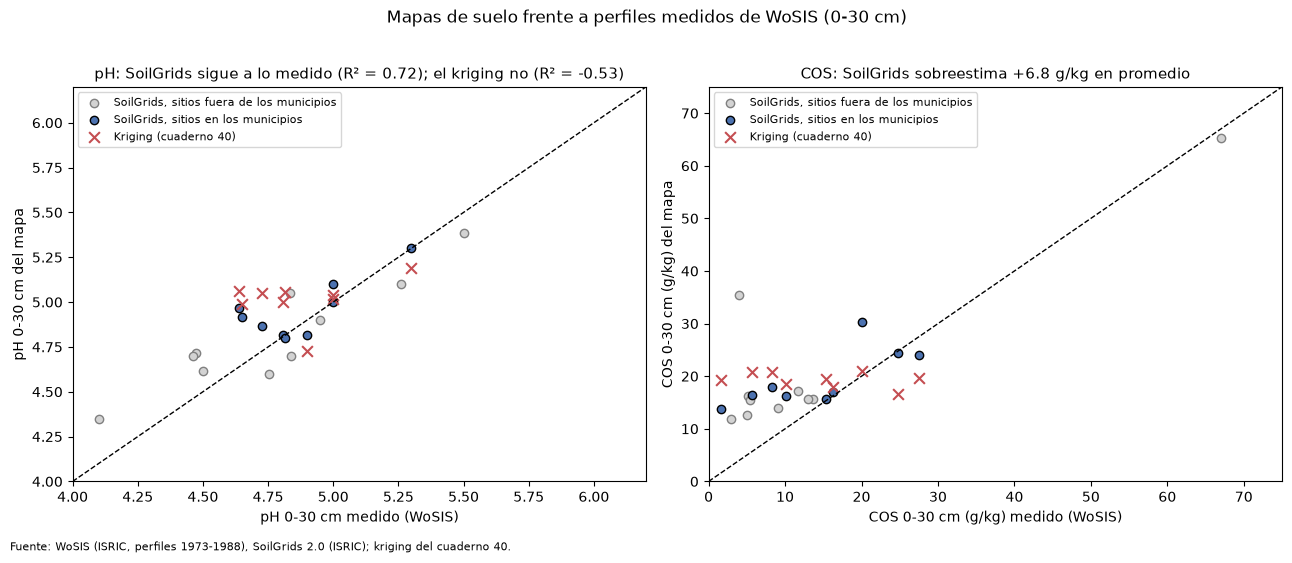

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5.2))
for a_, (obs_c, sg_c, kr_c, et, lim) in zip(ax, [
        ("ph", "ph_soilgrids", "ph_kriging", "pH 0-30 cm", (4.0, 6.2)),
        ("cos_gkg", "cos_soilgrids", "cos_kriging", "COS 0-30 cm (g/kg)", (0, 75))]):
    fuera = ~sitios["en_municipios"]
    a_.scatter(sitios.loc[fuera, obs_c], sitios.loc[fuera, sg_c], c="lightgrey", edgecolor="grey",
               label="SoilGrids, sitios fuera de los municipios")
    a_.scatter(sitios.loc[~fuera, obs_c], sitios.loc[~fuera, sg_c], c="#4C72B0", edgecolor="k",
               label="SoilGrids, sitios en los municipios")
    a_.scatter(sitios[obs_c], sitios[kr_c], marker="x", c="#C44E52", s=60, label="Kriging (cuaderno 40)")
    a_.plot(lim, lim, "k--", lw=1)
    a_.set_xlim(lim); a_.set_ylim(lim)
    a_.set_xlabel(f"{et} medido (WoSIS)"); a_.set_ylabel(f"{et} del mapa")
    a_.legend(fontsize=8, loc="upper left")
r_ph = val_wosis.query("propiedad == 'pH 0-30 cm' and sitios == 'caja (sitios con SoilGrids)'").iloc[0]
r_cos = val_wosis.query("propiedad == 'COS 0-30 cm (g/kg)' and sitios == 'caja (sitios con SoilGrids)'").iloc[0]
r_phk = val_wosis.query("propiedad == 'pH 0-30 cm' and mapa.str.startswith('Kriging')").iloc[0]
ax[0].set_title(f"pH: SoilGrids sigue a lo medido (R² = {r_ph['R2']:.2f}); el kriging no (R² = {r_phk['R2']:.2f})",
                fontsize=11)
ax[1].set_title(f"COS: SoilGrids sobreestima {r_cos['ME']:+.1f} g/kg en promedio", fontsize=11)
fig.suptitle("Mapas de suelo frente a perfiles medidos de WoSIS (0-30 cm)", y=1.02)
fuente("Fuente: WoSIS (ISRIC, perfiles 1973-1988), SoilGrids 2.0 (ISRIC); kriging del cuaderno 40.")
plt.tight_layout()
plt.savefig(GRAF / "41_wosis_vs_mapas.png", dpi=150, bbox_inches="tight")
plt.show()

**Lectura de la validación con WoSIS**

* **Pocos datos.** WoSIS tiene 79 perfiles en la caja y 35 dentro de los 7 municipios (Cumaribo 16, Puerto Gaitán 15, Puerto López 4), pero son solo **27 sitios distintos con dato 0-30 cm, y 9 dentro de los municipios**. Mapiripán, Puerto Carreño, La Primavera y Santa Rosalía no tienen ninguno. 8 sitios caen en el borde de la caja o sobre agua y no tienen valor de SoilGrids, así que la comparación con SoilGrids usa 19. Con tan pocos sitios, uno solo puede mover el R².
* **pH: SoilGrids acierta el nivel y el orden general.** Con los 19 sitios: RMSE = 0,17, ME = +0,06 (casi sin sesgo), R² = 0,72. Dentro de los municipios, donde el rango de pH medido es corto (4,6 a 5,3), el R² baja a 0,38 con RMSE = 0,16.
* **COS: SoilGrids sobreestima.** ME = **+6,8 g/kg** con los 19 sitios y +5,1 g/kg en los municipios (el carbono medido en los municipios promedia 14,4 g/kg). Es la misma sobreestimación que ya se veía en las versiones 03 y 04. Los perfiles son de 1972-1988 y el carbono superficial cambia con el uso, así que parte de la diferencia puede ser real.
* **El kriging es peor que SoilGrids frente a lo medido.** En los 9 sitios de los municipios: pH RMSE = 0,24 y R² = −0,53; COS RMSE = 10,1 g/kg y R² = −0,50. El kriging se hizo con 300 puntos de SoilGrids separados ~20 km, así que suaviza las diferencias locales que sí tiene SoilGrids.
* **El MSSE frente a WoSIS es mucho mayor que 1** (5,3 en pH y 37,9 en COS), mientras que frente a SoilGrids (cuaderno 40) daba 1,11 y 0,97. La varianza del kriging mide bien la incertidumbre de **interpolar SoilGrids**, pero no incluye el error de SoilGrids frente al suelo real. En el informe, los mapas de varianza se deben presentar como "incertidumbre de la interpolación", no como incertidumbre total.

## C. Concordancia con el mapa de pH del IGAC

El IGAC publica el mapa nacional **"Distribución y calidad de las propiedades químicas"** (obra *Suelos y Tierras de Colombia*, 2016, escala 1:100.000), hecho con 4.235 perfiles de los Levantamientos Generales de Suelos. Trae el pH en tres clases: ≤ 5,5, 5,6-7,0 y > 7,0. Los polígonos de Meta y Vichada se bajaron del servicio del IGAC en lotes de 100 (el servidor rechaza consultas grandes) y están en `datos/suelos/igac/` (DVC).

**Cómo se compara:** los polígonos se pintan (rasterizan) sobre la misma grilla de SoilGrids, dentro de los límites comunes. SoilGrids se clasifica con el mismo corte (pH ≤ 5,5 / > 5,5). Se reporta:

* **% de acuerdo**: píxeles donde los dos mapas dan la misma clase.
* **Kappa de Cohen**: acuerdo corregido por el que se daría por azar. 1 = perfecto; 0 = no mejor que el azar. Cuando una clase ocupa casi todo el territorio, el % de acuerdo es alto aunque los mapas no coincidan en nada más; el kappa lo revela.

In [7]:
traer("datos/suelos/igac")
pol = gpd.read_file(IGAC / "igac_ph_poligonos_meta_vichada.gpkg")
print(f"Polígonos del IGAC (Meta y Vichada): {len(pol):,}")
display(pol["pH"].value_counts(dropna=False).rename("polígonos").to_frame())

CODIGO = {"≤ 5.5": 1, "5.6 - 7.0": 2, "> 7.0": 3}
NOMBRE = {1: "≤ 5,5", 2: "5,6-7,0", 3: "> 7,0"}
with rasterio.open(SG / "soilgrids_ph_0_30.tif") as src:
    sg_ph = src.read(1).astype("float64")
    tr, crs_r, shape = src.transform, src.crs, src.shape
    if src.nodata is not None:
        sg_ph[sg_ph == src.nodata] = np.nan
with rasterio.open(SG / "soilgrids_cos_gkg_0_30.tif") as src:
    sg_cos = src.read(1).astype("float64")
    if src.nodata is not None:
        sg_cos[sg_cos == src.nodata] = np.nan
pol_r = pol.to_crs(crs_r)
igac = features.rasterize(((g, CODIGO.get(c, 9)) for g, c in zip(pol_r.geometry, pol_r["pH"])),
                          out_shape=shape, transform=tr, fill=0, dtype="uint8")
en_mun = features.geometry_mask(mun.to_crs(crs_r).geometry, out_shape=shape, transform=tr, invert=True)
valido = en_mun & np.isin(igac, [1, 2, 3]) & np.isfinite(sg_ph)
print(f"Píxeles dentro de los municipios: {en_mun.sum():,} | con clase IGAC y SoilGrids: {valido.sum():,} "
      f"({valido.sum() / en_mun.sum() * 100:.1f} %)")

df_ig = pd.DataFrame({"igac": igac[valido], "sg": sg_ph[valido]})
df_ig["sg_clase"] = np.select([df_ig["sg"] <= 5.5, df_ig["sg"] <= 7.0], [1, 2], 3)
etq = sorted(set(df_ig["igac"]) | set(df_ig["sg_clase"]))
tabla = pd.crosstab(df_ig["igac"].map(NOMBRE).rename("IGAC"), df_ig["sg_clase"].map(NOMBRE).rename("SoilGrids"))
print("Tabla de concordancia (% de los píxeles):")
display((tabla / tabla.values.sum() * 100).round(2))
acuerdo, kappa = kappa_cohen(df_ig["igac"], df_ig["sg_clase"], etq)
print(f"Acuerdo global = {acuerdo * 100:.1f} % | kappa de Cohen = {kappa:.3f}")
display(df_ig.groupby(df_ig["igac"].map(NOMBRE).rename("clase IGAC"))["sg"].describe().round(2)
        .rename(columns={"mean": "pH SoilGrids medio"}))

conc = pd.DataFrame([{"comparacion": "IGAC vs SoilGrids, clases de pH (corte 5,5)", "pixeles": int(valido.sum()),
                      "acuerdo_pct": acuerdo * 100, "kappa": kappa,
                      "pct_area_igac_mayor_5_5": (df_ig["igac"] >= 2).mean() * 100,
                      "pct_area_soilgrids_mayor_5_5": (df_ig["sg_clase"] >= 2).mean() * 100}])
conc.to_csv(RES / "41_igac_concordancia.csv", index=False)

Polígonos del IGAC (Meta y Vichada): 12,555


,polígonos
pH,
≤ 5.5,9596
Cuerpos de agua,2440
5.6 - 7.0,505
Zonas urbanas,14


Píxeles dentro de los municipios: 1,765,825 | con clase IGAC y SoilGrids: 1,731,345 (98.0 %)
Tabla de concordancia (% de los píxeles):


SoilGrids,"5,6-7,0","≤ 5,5"
IGAC,,
"5,6-7,0",0.00,2.04
"≤ 5,5",0.07,97.89


Acuerdo global = 97.9 % | kappa de Cohen = -0.001


,count,pH SoilGrids medio,std,min,25%,50%,75%,max
clase IGAC,,,,,,,,
"5,6-7,0",35344.0,4.88,0.18,4.50,4.72,4.82,5.02,5.6
"≤ 5,5",1696001.0,5.02,0.22,4.25,4.80,5.10,5.20,5.7


### C.2 Suelo por paisaje (antes sección D.3 del cuaderno 40)

El mapa del IGAC también trae el **paisaje** de cada unidad de suelo (altiplanicie, lomerío, planicie, valle...). Se promedian el pH y el COS de SoilGrids en cada paisaje para ver si el modelo distingue los paisajes que la cartografía oficial separa.

In [8]:
paisajes = pol_r["PAISAJE"].fillna("sin dato").astype(str).str.strip().str.capitalize()
cod_p = {p: i + 1 for i, p in enumerate(sorted(paisajes.unique()))}
r_p = features.rasterize(((g, cod_p[p]) for g, p in zip(pol_r.geometry, paisajes)),
                         out_shape=shape, transform=tr, fill=0, dtype="uint16")
v = en_mun & (r_p > 0) & np.isfinite(sg_ph) & np.isfinite(sg_cos)
inv = {i: p for p, i in cod_p.items()}
dp = pd.DataFrame({"paisaje": pd.Series(r_p[v]).map(inv).values, "ph": sg_ph[v], "cos": sg_cos[v],
                   "igac_mayor_5_5": (igac[v] >= 2) & (igac[v] <= 3)})
por_paisaje = dp.groupby("paisaje").agg(pct_area=("ph", "size"), ph_medio=("ph", "mean"),
                                        pct_ph_menor_5=("ph", lambda s: (s < 5).mean() * 100),
                                        cos_medio_gkg=("cos", "mean"),
                                        pct_igac_ph_mayor_5_5=("igac_mayor_5_5", lambda s: s.mean() * 100))
por_paisaje["pct_area"] = por_paisaje["pct_area"] / por_paisaje["pct_area"].sum() * 100
por_paisaje = por_paisaje.sort_values("pct_area", ascending=False)
por_paisaje.round(3).to_csv(RES / "41_suelo_por_paisaje.csv")
display(por_paisaje.round(2))

,pct_area,ph_medio,pct_ph_menor_5,cos_medio_gkg,pct_igac_ph_mayor_5_5
paisaje,,,,,
Altiplanicie,41.78,5.16,3.50,20.15,0.00
Lomerío,31.30,4.91,57.07,18.41,4.32
Valle,10.68,5.01,32.86,20.06,0.00
Peniplanicie,9.16,4.91,57.99,20.43,0.00
Planicie aluvial,5.51,4.72,81.87,19.26,12.25
Cuerpos de agua,0.72,5.04,30.47,23.17,0.00
Macizo,0.70,4.76,88.59,18.67,0.00
Piedemonte,0.14,5.16,6.98,25.12,0.00
Zonas urbanas,0.01,5.12,0.81,19.34,0.00


## D. Mapas finales

### D.1 Predicción y varianza del kriging (pH y COS)

Mapas del cuaderno 40 en la grilla común de 2 km, con los sitios de WoSIS encima. Estos son los mapas que van al informe y a la presentación.

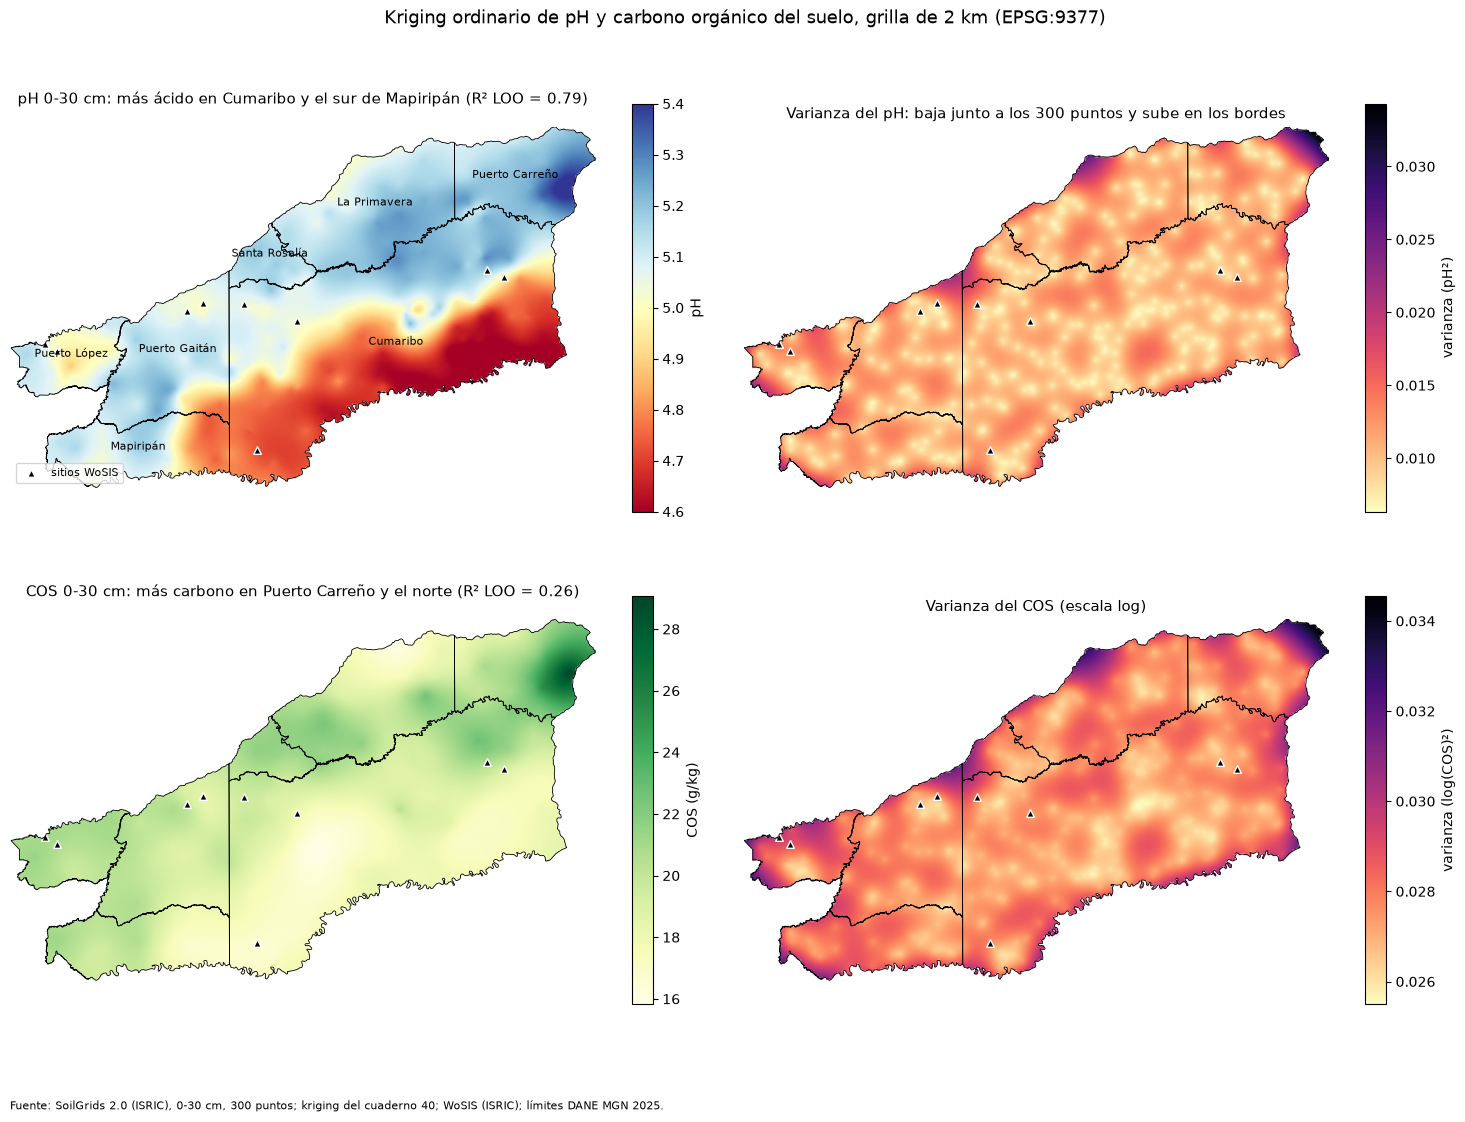

In [9]:
def leer(f):
    with rasterio.open(f) as src:
        a = src.read(1).astype("float64")
        b = src.bounds
    a[~np.isfinite(a)] = np.nan
    return a, [b.left, b.right, b.bottom, b.top]


ph_k, ext = leer(SG / "kriging_ph_0_30.tif")
ph_v, _ = leer(SG / "kriging_ph_0_30_varianza.tif")
cos_k, _ = leer(SG / "kriging_cos_0_30_gkg.tif")
cos_v, _ = leer(SG / "kriging_cos_0_30_varianza_log.tif")
sitios_m = sitios.to_crs(CRS_M)

res40 = pd.read_csv(SG / "resumen_validacion_soilgrids.csv")
r2_ph = res40.loc[res40["propiedad"].str.startswith("pH"), "R2_LOO"].iloc[0]
r2_cos = res40.loc[res40["propiedad"].str.startswith("COS"), "R2_LOO"].iloc[0]

fig, ax = plt.subplots(2, 2, figsize=(15, 11))
paneles = [
    (ph_k, f"pH 0-30 cm: más ácido en Cumaribo y el sur de Mapiripán (R² LOO = {r2_ph:.2f})", "RdYlBu", "pH", 4.6, 5.4),
    (ph_v, "Varianza del pH: baja junto a los 300 puntos y sube en los bordes", "magma_r", "varianza (pH²)", None, None),
    (cos_k, f"COS 0-30 cm: más carbono en Puerto Carreño y el norte (R² LOO = {r2_cos:.2f})", "YlGn", "COS (g/kg)", None, None),
    (cos_v, "Varianza del COS (escala log)", "magma_r", "varianza (log(COS)²)", None, None)]
for a_, (arr, tit, cmap, lab, v0, v1) in zip(ax.ravel(), paneles):
    im = a_.imshow(arr, extent=ext, cmap=cmap, vmin=v0, vmax=v1)
    plt.colorbar(im, ax=a_, shrink=0.75, label=lab)
    mun_m.boundary.plot(ax=a_, color="k", lw=0.6)
    sitios_m[sitios_m["en_municipios"]].plot(ax=a_, color="k", marker="^", markersize=30,
                                            edgecolor="white", label="sitios WoSIS")
    a_.set_title(tit, fontsize=11)
    a_.set_xlim(ext[0], ext[1]); a_.set_ylim(ext[2], ext[3]); a_.set_axis_off()
for _, r in mun_m.iterrows():
    p = r.geometry.representative_point()
    ax[0, 0].annotate(r["municipio"], (p.x, p.y), fontsize=8, ha="center")
ax[0, 0].legend(loc="lower left", fontsize=8)
fig.suptitle("Kriging ordinario de pH y carbono orgánico del suelo, grilla de 2 km (EPSG:9377)", fontsize=13)
fuente("Fuente: SoilGrids 2.0 (ISRIC), 0-30 cm, 300 puntos; kriging del cuaderno 40; WoSIS (ISRIC); límites DANE MGN 2025.")
plt.tight_layout()
plt.savefig(GRAF / "41_mapas_kriging_prediccion_varianza.png", dpi=200, bbox_inches="tight")
plt.show()

### D.2 Clases de pH: ¿qué clases aparecen realmente?

La ruta de trabajo (sección 14.3) pide confirmar qué clases de acidez existen en la región antes de comparar zonas "ácidas" y "menos ácidas". Se clasifica cada píxel de SoilGrids (≈ 278 m) con los mismos cortes del cuaderno 42 y se calcula el % del área de cada municipio en cada clase.

% del área en cada clase de pH (píxeles de SoilGrids 0-30 cm):


,"extremadamente ácido (< 4,5)","muy fuertemente ácido (4,5-5,0)","fuertemente ácido (5,0-5,5]","moderadamente ácido o más (> 5,5)"
municipio,,,,
Cumaribo,0.5,59.8,39.6,0.1
La Primavera,0.0,5.6,94.4,0.0
Mapiripán,0.0,62.9,37.1,0.0
Puerto Carreño,0.0,3.6,96.1,0.3
Puerto Gaitán,0.0,13.8,86.2,0.0
Puerto López,0.0,22.8,77.2,0.0
Santa Rosalía,0.0,9.0,91.0,0.0
Altillanura (7 municipios),0.2,38.6,61.1,0.1


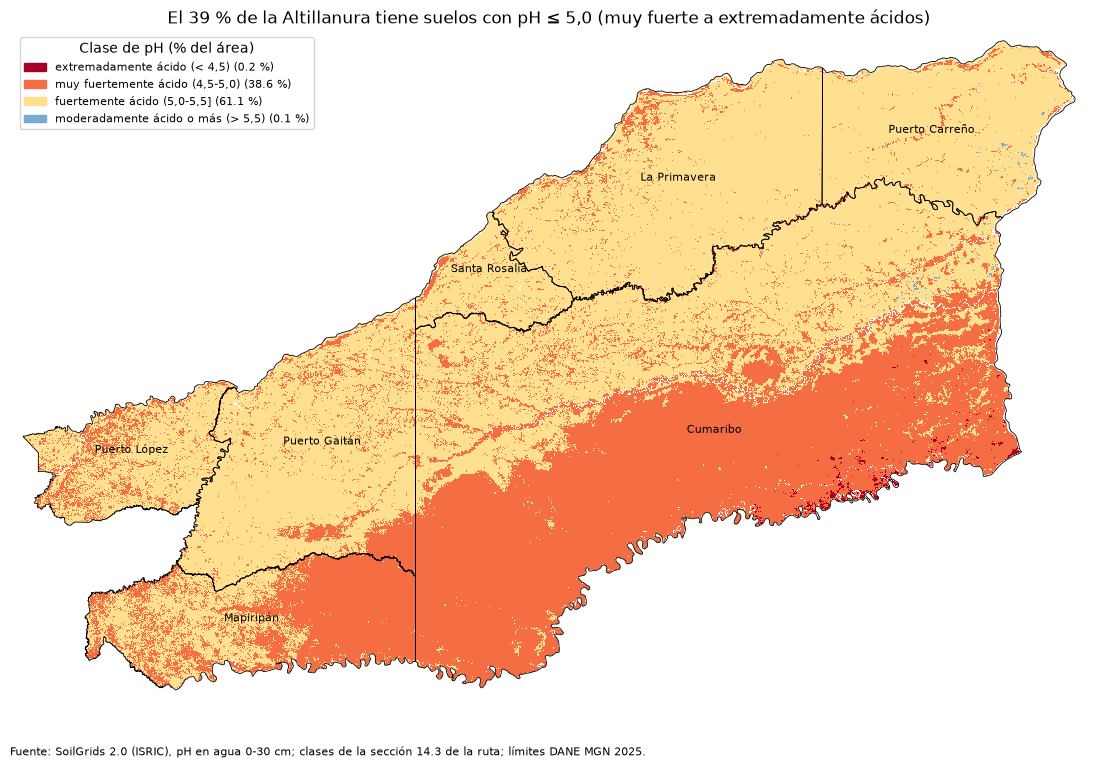

In [10]:
validos = en_mun & np.isfinite(sg_ph)
# Mismos cortes que el cuaderno 42: < 4,5 | 4,5 ≤ pH ≤ 5,0 | 5,0 < pH ≤ 5,5 | > 5,5
clase_px = np.where(validos, np.select([sg_ph < 4.5, sg_ph <= 5.0, sg_ph <= 5.5], [0, 1, 2], 3), np.nan)
idx_mun = features.rasterize(((g, i + 1) for i, g in enumerate(mun.to_crs(crs_r).geometry)),
                             out_shape=shape, transform=tr, fill=0, dtype="uint8")
d = pd.DataFrame({"municipio": mun["municipio"].values[idx_mun[validos] - 1], "clase": clase_px[validos].astype(int)})
area = pd.crosstab(d["municipio"], d["clase"], normalize="index") * 100
area.loc["Altillanura (7 municipios)"] = pd.Series(d["clase"]).value_counts(normalize=True).sort_index() * 100
area = area.reindex(columns=range(len(CLASES_PH)), fill_value=0)
area.columns = [c[2] for c in CLASES_PH]
area.round(2).to_csv(RES / "41_clases_ph_area.csv")
print("% del área en cada clase de pH (píxeles de SoilGrids 0-30 cm):")
display(area.round(1))

colores = ["#a50026", "#f46d43", "#fee090", "#74add1"]
fig, ax = plt.subplots(figsize=(11, 7.5))
ext_r = [tr.c, tr.c + tr.a * shape[1], tr.f + tr.e * shape[0], tr.f]
ax.imshow(clase_px, extent=ext_r, cmap=ListedColormap(colores), norm=BoundaryNorm([-0.5, 0.5, 1.5, 2.5, 3.5], 4),
          interpolation="nearest")
mun.to_crs(crs_r).boundary.plot(ax=ax, color="k", lw=0.6)
for _, r in mun.to_crs(crs_r).iterrows():
    p = r.geometry.representative_point()
    ax.annotate(r["municipio"], (p.x, p.y), fontsize=8, ha="center")
tot = area.loc["Altillanura (7 municipios)"]
ax.legend(handles=[Patch(color=c, label=f"{n} ({tot[n]:.1f} %)") for c, n in zip(colores, area.columns)],
          loc="upper left", fontsize=8, title="Clase de pH (% del área)")
b = mun.to_crs(crs_r).total_bounds
ax.set_xlim(b[0] - 0.05, b[2] + 0.05); ax.set_ylim(b[1] - 0.05, b[3] + 0.05); ax.set_axis_off()
pct_muy = tot.iloc[0] + tot.iloc[1]
ax.set_title(f"El {pct_muy:.0f} % de la Altillanura tiene suelos con pH ≤ 5,0 (muy fuerte a extremadamente ácidos)")
fuente("Fuente: SoilGrids 2.0 (ISRIC), pH en agua 0-30 cm; clases de la sección 14.3 de la ruta; límites DANE MGN 2025.")
plt.tight_layout()
plt.savefig(GRAF / "41_mapa_clases_ph.png", dpi=200, bbox_inches="tight")
plt.show()

## E. Tabla final de validación

Junta en una sola tabla la **validación interna** del cuaderno 40 (kriging contra SoilGrids: LOO, validación independiente y benchmark IDW) y la **validación externa** de este cuaderno (contra WoSIS y contra el IGAC). Es la tabla que va al informe.

In [11]:
filas = []
for _, r in res40.iterrows():
    for etapa, suf in [("LOO (300 puntos)", "_LOO"), ("validación independiente (200 puntos)", "_valid")]:
        filas.append({"propiedad": r["propiedad"], "validacion": "interna: kriging vs SoilGrids", "conjunto": etapa,
                      "metodo": f"kriging ordinario ({r['modelo']})", "n": r["n_puntos"],
                      "RMSE": r[f"RMSE{suf}"], "MAE": r[f"MAE{suf}"], "ME": r[f"ME{suf}"], "R2": r[f"R2{suf}"],
                      "MSSE": r["MSSE_LOO"] if suf == "_LOO" else np.nan,
                      "pepita_meseta": r["pepita/meseta"], "rango_km": r["rango_km"]})
bench = pd.read_csv(SG / "benchmark_idw_vs_kriging.csv")
display(bench.head())
for _, r in val_wosis.iterrows():
    filas.append({"propiedad": r["propiedad"], "validacion": "externa: vs WoSIS (medido)", "conjunto": r["sitios"],
                  "metodo": r["mapa"], "n": r["n"], "RMSE": r["RMSE"], "MAE": r["MAE"], "ME": r["ME"],
                  "R2": r["R2"], "MSSE": r["MSSE"]})
filas.append({"propiedad": "pH (clases, corte 5,5)", "validacion": "externa: vs mapa IGAC 2016",
              "conjunto": "píxeles de los 7 municipios", "metodo": "SoilGrids 250 m", "n": int(valido.sum()),
              "acuerdo_pct": acuerdo * 100, "kappa": kappa})
tabla_val = pd.DataFrame(filas)
tabla_val.round(4).to_csv(RES / "41_tabla_validacion.csv", index=False)
sitios.drop(columns="geometry").round(4).to_csv(RES / "41_wosis_sitios.csv", index=False)
display(tabla_val.round(3))
print("Guardado en", RES)

,propiedad,método,conjunto,RMSE,MAE,ME,R2
0,pH,IDW p=2,LOO,0.118192,0.094700,0.000236,0.734743
1,pH,Kriging ordinario,LOO,0.106091,0.080567,0.000452,0.786281
2,pH,IDW p=2,validación,0.122704,0.096283,-0.022450,0.696021
3,pH,Kriging ordinario,validación,0.114291,0.081648,-0.008346,0.736275
4,COS (g/kg),IDW p=2,LOO,3.566929,2.477158,-0.247218,0.279334


,propiedad,validacion,conjunto,metodo,n,RMSE,MAE,ME,R2,MSSE,pepita_meseta,rango_km,acuerdo_pct,kappa
0,COS 0-30 cm (g/kg; kriging en log),interna: kriging vs SoilGrids,LOO (300 puntos),kriging ordinario (exponencial),300,3.623,2.512,-0.034,0.256,0.966,0.594,213.244,NaN,NaN
1,COS 0-30 cm (g/kg; kriging en log),interna: kriging vs SoilGrids,validación independiente (200 puntos),kriging ordinario (exponencial),300,4.300,2.930,-0.270,0.115,NaN,0.594,213.244,NaN,NaN
2,pH 0-30 cm,interna: kriging vs SoilGrids,LOO (300 puntos),kriging ordinario (esférico),300,0.106,0.081,0.000,0.786,1.114,0.070,212.769,NaN,NaN
3,pH 0-30 cm,interna: kriging vs SoilGrids,validación independiente (200 puntos),kriging ordinario (esférico),300,0.114,0.082,-0.008,0.736,NaN,0.070,212.769,NaN,NaN
4,pH 0-30 cm,externa: vs WoSIS (medido),caja (sitios con SoilGrids),SoilGrids 250 m,19,0.168,0.138,0.063,0.719,NaN,NaN,NaN,NaN,NaN
5,pH 0-30 cm,externa: vs WoSIS (medido),7 municipios,SoilGrids 250 m,9,0.155,0.105,0.083,0.383,NaN,NaN,NaN,NaN,NaN
6,pH 0-30 cm,externa: vs WoSIS (medido),7 municipios,Kriging ordinario 2 km (cuaderno 40),9,0.244,0.205,0.143,-0.533,5.292,NaN,NaN,NaN,NaN
7,COS 0-30 cm (g/kg),externa: vs WoSIS (medido),caja (sitios con SoilGrids),SoilGrids 250 m,19,10.076,7.368,6.770,0.507,NaN,NaN,NaN,NaN,NaN
8,COS 0-30 cm (g/kg),externa: vs WoSIS (medido),7 municipios,SoilGrids 250 m,9,7.583,6.020,5.141,0.155,NaN,NaN,NaN,NaN,NaN
9,COS 0-30 cm (g/kg),externa: vs WoSIS (medido),7 municipios,Kriging ordinario 2 km (cuaderno 40),9,10.100,8.511,4.949,-0.499,37.882,NaN,NaN,NaN,NaN


Guardado en c:\Proyectos\Proyecto-ALTILLANURA\modulos\suelos\resultados


## F. Conclusiones

1. **Validación externa con WoSIS (27 sitios, 9 en los municipios, perfiles de 1972-1988).** SoilGrids representa bien el pH de la región (RMSE = 0,17; ME = +0,06; R² = 0,72 con 19 sitios) y **sobreestima el carbono orgánico en +6,8 g/kg** (+5,1 g/kg en los municipios). Por eso el pH de SoilGrids se puede usar en la integración con confianza razonable, y el COS conviene leerlo como un valor relativo (dónde hay más o menos), no como cifra absoluta.
2. **El kriging del 40 no mejora a SoilGrids frente a lo medido**: en los 9 sitios de los municipios da R² negativo en pH (−0,53) y COS (−0,50). Es lo esperado, porque es un ejercicio metodológico sobre puntos de SoilGrids (advertencia de la sección 11.4 de la ruta). Para describir el suelo de cada celda se usa el promedio de los píxeles de SoilGrids (cuaderno 42), no el kriging.
3. **La varianza del kriging está bien calibrada para la interpolación (MSSE ≈ 1 en el 40) pero no para el error total** (MSSE = 5,3 en pH y 37,9 en COS frente a WoSIS).
4. **Concordancia con el IGAC: 97,9 % de acuerdo, pero kappa = 0,00.** El 98 % del territorio es pH ≤ 5,5 en los dos mapas, y ahí está todo el acuerdo. En el 2 % que el IGAC marca como 5,6-7,0 (vegas y planicie aluvial), SoilGrids da en promedio pH 4,88, **más ácido** que en el resto (5,02). SoilGrids no detecta las zonas menos ácidas de la cartografía oficial.
5. **Por paisaje (cartografía IGAC):** la **altiplanicie** (42 % del área) es la menos ácida (pH 5,16; solo 3,5 % del área con pH < 5); el **lomerío** (31 %), la **peniplanicie** (9 %) y la **planicie aluvial** (6 %) son más ácidos (pH 4,72-4,91; 57-82 % del área con pH < 5). El COS casi no cambia entre paisajes (18-20 g/kg).
6. **Clases de pH que existen (respuesta a la sección 14.3):** en la práctica hay **dos clases**: fuertemente ácido, 5,0-5,5 (**61,1 %** del área) y muy fuertemente ácido, 4,5-5,0 (**38,6 %**). La extremadamente ácida (< 4,5; 0,2 %) y la moderadamente ácida o más (> 5,5; 0,1 %) son marginales. La comparación "ácido vs. menos ácido" de la integración es, entonces, **pH ≤ 5,0 frente a 5,0-5,5**. Los municipios más ácidos son Mapiripán (62,9 % del área con pH ≤ 5,0) y Cumaribo (60,3 %); los menos ácidos, Puerto Carreño (3,6 %) y La Primavera (5,6 %).
7. **Salidas para el informe:** `41_tabla_validacion.csv` (validación interna y externa en una tabla), `41_mapas_kriging_prediccion_varianza.png` y `41_mapa_clases_ph.png` (mapas finales), `41_wosis_vs_mapas.png`.
8. **Limitación principal:** no hay perfiles medidos recientes y bien ubicados en la Altillanura. Los perfiles modales de los Estudios Generales de Suelos del IGAC (~120 en los 7 municipios) serían la siguiente fuente para una validación más fuerte.